# 02 Baselines

- **Model 0:** majority class, the floor every model must beat.
- **Model 1:** logistic regression on TF-IDF character 1-3-grams of the domain.

Data: the saved splits in `data/splits/` (made by `00_data_splits.ipynb`, checked against `manifest.json`).

Model 1 is run in two setups: **binary** (target DGA/legitimate) and **family-first** (target `legit` or a DGA family, collapsed with P(DGA) = 1 - P(legit)); with and without the TLD (removed with `tldextract`); and **with and without sample weights**, to see what the weighting changes. Metrics are computed on the DGA/legitimate decision, on the validation set; the test set is kept for the final results.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

## Settings

`SAMPLE` trains on a random subset of the training set for quick runs; set it to `None` to use all 1.6M rows (the family setup then takes much longer).

In [2]:
import os

SAMPLE = 100_000   # None = full training set
SEED = 0
EVAL_SET = "val"   # "test" only for the final results
N_JOBS = os.cpu_count()   # use every core for tldextract and the model fits

In [3]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tldextract
from joblib import Parallel, delayed
import scipy.sparse as sp
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

from src.data.dataset import load_splits

train_full, val, test = load_splits()
train = train_full.sample(n=SAMPLE, random_state=SEED) if SAMPLE else train_full
evaluate = test if EVAL_SET == "test" else val
y_eval = (evaluate["label"] == "dga").astype(int).to_numpy()
print(f"train: {len(train):,} rows (of {len(train_full):,}), "
      f"{EVAL_SET}: {len(evaluate):,} rows")

train: 100,000 rows (of 1,599,468), val: 199,933 rows


## Data overview

A look at the data before training. All plots use the full training set unless stated otherwise.

In [4]:
# Chart style: two fixed colours (legitimate = blue, DGA = orange), recessive axes.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
COLORS = {"legit": BLUE, "dga": ORANGE}
NAMES = {"legit": "legitimate", "dga": "DGA"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 9,
})

### Class balance and family sizes

Every split is half legitimate, half DGA. Family sizes still differ a lot (240 to 23,296 training domains), which is what the sample weights correct.

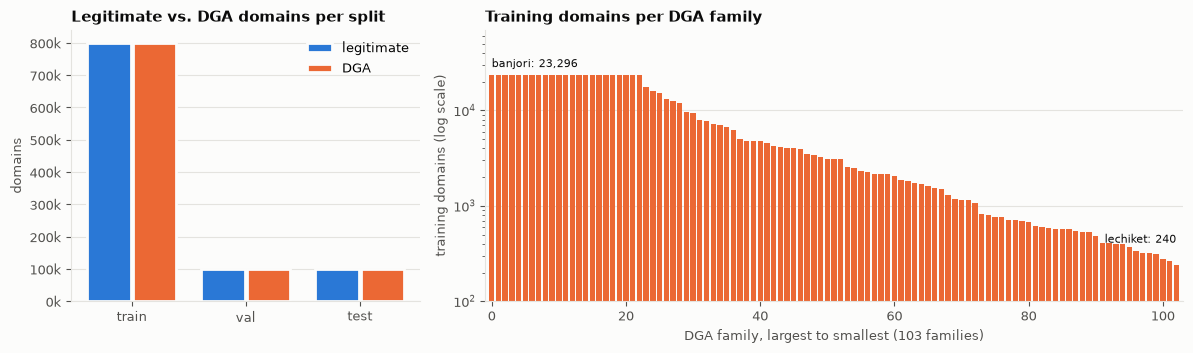

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6), width_ratios=[1, 2])

split_counts = pd.DataFrame({name: part["label"].value_counts() for name, part in
                             [("train", train_full), ("val", val), ("test", test)]}).T
x = np.arange(len(split_counts))
for offset, label in [(-0.2, "legit"), (0.2, "dga")]:
    bars = ax1.bar(x + offset, split_counts[label], width=0.38, color=COLORS[label],
                   label=NAMES[label], edgecolor=SURFACE, linewidth=2)
ax1.set_xticks(x, split_counts.index)
ax1.yaxis.set_major_formatter(lambda v, _: f"{v / 1e3:,.0f}k")
ax1.set_ylabel("domains")
ax1.set_title("Legitimate vs. DGA domains per split")
ax1.legend(loc="upper right")
ax1.grid(axis="x", visible=False)

family_sizes = train_full.loc[train_full["label"] == "dga", "family"].value_counts()
ax2.bar(np.arange(len(family_sizes)), family_sizes.values, width=0.8, color=ORANGE)
ax2.set_yscale("log")
ax2.set_ylim(100, family_sizes.max() * 3)
ax2.set_xlim(-1, len(family_sizes))
ax2.set_xlabel(f"DGA family, largest to smallest ({len(family_sizes)} families)")
ax2.set_ylabel("training domains (log scale)")
ax2.set_title("Training domains per DGA family")
ax2.grid(axis="x", visible=False)
for i in [0, len(family_sizes) - 1]:
    ax2.annotate(f"{family_sizes.index[i]}: {family_sizes.iloc[i]:,}",
                 (i, family_sizes.iloc[i]), xytext=(0, 6 if i == 0 else 16),
                 textcoords="offset points",
                 ha="left" if i == 0 else "right", color=INK, fontsize=8)
fig.tight_layout()
plt.show()

### Domain length and TLDs

DGA domains are longer on average and use a different set of TLDs. The TLD is extracted with `tldextract`; BazarBackdoor and Necurs use TLDs outside the public suffix list (`.bazar`, `.bit`), for which the last label is taken as the TLD.

tldextract on 1,999,335 domains with 14 processes: 8 s


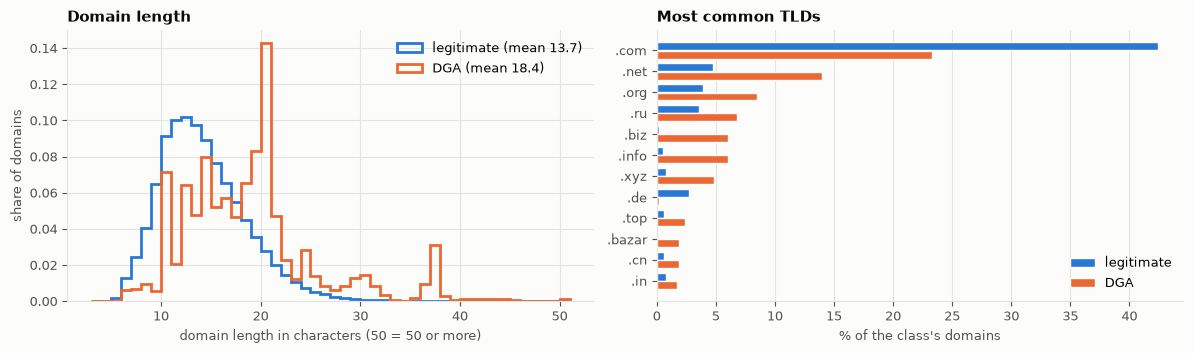

distinct TLDs: legitimate 2290, DGA 282


In [6]:
def split_tld_batch(domains):
    """name and tld of each domain: google.com -> (google, com), bbc.co.uk -> (bbc, co.uk).

    Uses the suffix list bundled with tldextract (no download), so every machine
    splits domains the same way. TLDs outside the public suffix list (.bazar, .bit:
    BazarBackdoor and Necurs use alternative DNS roots) get the last label as TLD.
    """
    extract = tldextract.TLDExtract(suffix_list_urls=())
    results = map(extract, domains)
    parts = pd.DataFrame([(r.subdomain, r.domain, r.suffix) for r in results],
                         columns=["subdomain", "domain", "suffix"], index=domains)
    name = (parts["subdomain"] + "." + parts["domain"]).str.strip(".")
    last = parts.index.to_series().str.rpartition(".")
    no_suffix = parts["suffix"] == ""
    return pd.DataFrame({"name": name.where(~no_suffix, last[0]),
                         "tld": parts["suffix"].where(~no_suffix, last[2])})


# Every domain of all three splits, split once: unique domains in one batch per core.
all_domains = pd.concat([train_full["domain"], val["domain"], test["domain"]]).unique()
start = time.time()
tld_table = pd.concat(Parallel(n_jobs=N_JOBS)(
    delayed(split_tld_batch)(chunk) for chunk in np.array_split(all_domains, N_JOBS)))
print(f"tldextract on {len(tld_table):,} domains with {N_JOBS} processes: "
      f"{time.time() - start:.0f} s")


def strip_tld(domains):
    return domains.map(tld_table["name"])


train_full["tld"] = train_full["domain"].map(tld_table["tld"])
train_full["length"] = train_full["domain"].str.len()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))

bins = np.arange(3, 52)
for label in ["legit", "dga"]:
    lengths = train_full.loc[train_full["label"] == label, "length"].clip(upper=50)
    ax1.hist(lengths, bins=bins, density=True, histtype="step", linewidth=2,
             color=COLORS[label], label=f"{NAMES[label]} (mean {lengths.mean():.1f})")
ax1.set_xlabel("domain length in characters (50 = 50 or more)")
ax1.set_ylabel("share of domains")
ax1.set_title("Domain length")
ax1.legend()

tld_share = (train_full.groupby("label")["tld"].value_counts(normalize=True)
             .unstack(0).fillna(0))
top = tld_share.max(axis=1).sort_values(ascending=False).head(12).index[::-1]
y = np.arange(len(top))
for offset, label in [(0.2, "legit"), (-0.2, "dga")]:
    ax2.barh(y + offset, tld_share.loc[top, label] * 100, height=0.38,
             color=COLORS[label], label=NAMES[label], edgecolor=SURFACE, linewidth=1)
ax2.set_yticks(y, [f".{t}" for t in top])
ax2.set_xlabel("% of the class's domains")
ax2.set_title("Most common TLDs")
ax2.legend(loc="lower right")
ax2.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

n_tlds = train_full.groupby("label")["tld"].nunique()
print(f"distinct TLDs: legitimate {n_tlds['legit']}, DGA {n_tlds['dga']}")

### What the sample weights do

Without weights, each DGA family counts in proportion to its size, so the largest families dominate training. With weights (legitimate and DGA half each; within DGA proportional to 1/sqrt(family size)), the share of each family is flattened: small families count more, but at most 9.9 times more per domain than the largest.

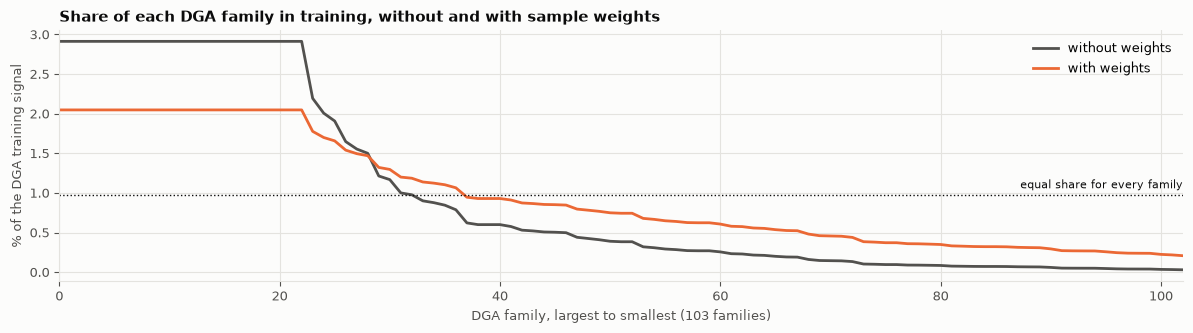

largest family share: 2.91% -> 2.05% with weights
smallest family share: 0.030% -> 0.208% with weights


In [7]:
dga_train = train_full[train_full["label"] == "dga"]
share = pd.DataFrame({
    "without weights": dga_train["family"].value_counts(normalize=True),
    "with weights": dga_train.groupby("family")["weight"].sum() / dga_train["weight"].sum(),
}).loc[family_sizes.index] * 100

fig, ax = plt.subplots(figsize=(12, 3.4))
x = np.arange(len(share))
for column, color in [("without weights", MUTED), ("with weights", ORANGE)]:
    ax.plot(x, share[column], color=color, linewidth=2, label=column)
ax.axhline(100 / len(share), color=INK, linewidth=1, linestyle=":")
ax.annotate("equal share for every family", (len(share) - 1, 100 / len(share)),
            xytext=(0, 5), textcoords="offset points", ha="right", color=INK, fontsize=8)
ax.set_xlim(0, len(share) - 1)
ax.set_xlabel(f"DGA family, largest to smallest ({len(share)} families)")
ax.set_ylabel("% of the DGA training signal")
ax.set_title("Share of each DGA family in training, without and with sample weights")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

print(f"largest family share: {share['without weights'].iloc[0]:.2f}% -> "
      f"{share['with weights'].iloc[0]:.2f}% with weights")
print(f"smallest family share: {share['without weights'].iloc[-1]:.3f}% -> "
      f"{share['with weights'].iloc[-1]:.3f}% with weights")

## Metrics

In [8]:
def binary_metrics(y_true, p_dga, threshold=0.5):
    y_pred = (p_dga >= threshold).astype(int)
    auc = roc_auc_score(y_true, p_dga) if len(np.unique(p_dga)) > 1 else 0.5
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "dga_precision": precision_score(y_true, y_pred, zero_division=0),
        "dga_recall": recall_score(y_true, y_pred),
        "roc_auc": auc,
    }


def recall_per_family(families, y_true, y_pred):
    dga = y_true == 1
    hit = pd.Series(y_pred[dga] == 1, index=families.to_numpy()[dga])
    return hit.groupby(level=0).mean()

## Model 0: majority class

In [9]:
majority = train["label"].value_counts().idxmax()
p_majority = np.full(len(evaluate), float(majority == "dga"))
results = {("Model 0", "-", "-", "-"): binary_metrics(y_eval, p_majority)}
print("majority class:", majority)

majority class: legit


## Model 1: logistic regression

Eight runs: 2 setups x with/without TLD x with/without sample weights. The TF-IDF features are computed once per input (with and without TLD), and the eight fits run in parallel, one per core.

In [10]:
NGRAMS = dict(analyzer="char", ngram_range=(1, 3))
MIN_DF = 5


def batches(texts):
    return np.array_split(np.asarray(texts), N_JOBS)


def doc_freq(texts):
    """In how many domains of this batch each n-gram occurs."""
    vec = CountVectorizer(**NGRAMS, binary=True)
    counts = vec.fit_transform(texts)
    return pd.Series(np.asarray(counts.sum(axis=0)).ravel(), index=vec.get_feature_names_out())


def count_ngrams(texts, vocabulary):
    return CountVectorizer(**NGRAMS, vocabulary=vocabulary).transform(texts)


def tfidf(x_train, x_eval):
    """TfidfVectorizer(char 1-3-grams, min_df=5, sublinear_tf), built in batches on every core."""
    with Parallel(n_jobs=N_JOBS) as parallel:
        df = pd.concat(parallel(delayed(doc_freq)(b) for b in batches(x_train)))
        df = df.groupby(level=0).sum()
        vocabulary = df.index[df >= MIN_DF]   # sorted, as in TfidfVectorizer
        train_counts, eval_counts = (
            sp.vstack(parallel(delayed(count_ngrams)(b, vocabulary) for b in batches(x)))
            for x in (x_train, x_eval))
    idf = TfidfTransformer(sublinear_tf=True).fit(train_counts)
    return idf.transform(train_counts), idf.transform(eval_counts)


start = time.time()
features = {True: tfidf(train["domain"], evaluate["domain"]),
            False: tfidf(strip_tld(train["domain"]), strip_tld(evaluate["domain"]))}
print(f"TF-IDF features: {features[True][0].shape[1]:,} n-grams with TLD, "
      f"{features[False][0].shape[1]:,} without ({time.time() - start:.0f} s)")


def fit_logreg(x_train, x_eval, target, weights):
    start = time.time()
    clf = LogisticRegression(max_iter=300, random_state=SEED)
    clf.fit(x_train, target, sample_weight=weights)
    proba = clf.predict_proba(x_eval)
    return 1 - proba[:, list(clf.classes_).index("legit")], time.time() - start   # P(DGA)


grid = [(setup, tld, weighted) for setup in ["binary", "family"]
        for tld in [True, False] for weighted in [False, True]]
start = time.time()
fits = Parallel(n_jobs=min(N_JOBS, len(grid)))(
    delayed(fit_logreg)(*features[tld],
                        train["label"] if setup == "binary" else train["family"],
                        train["weight"] if weighted else None)
    for setup, tld, weighted in grid)
print(f"{len(grid)} fits in parallel: {time.time() - start:.0f} s")

p_dga = {}
for (setup, tld, weighted), (p, seconds) in zip(grid, fits):
    p_dga[setup, tld, weighted] = p
    key = ("Model 1", setup, "yes" if tld else "no", "yes" if weighted else "no")
    results[key] = {**binary_metrics(y_eval, p), "fit_s": round(seconds)}

TF-IDF features: 31,514 n-grams with TLD, 29,354 without (14 s)


8 fits in parallel: 399 s


## Results (DGA/legitimate decision)

In [11]:
table = pd.DataFrame(results).T.round(4)
table.index.names = ["model", "setup", "TLD", "weights"]
table

macro_f1  dga_precision  dga_recall  roc_auc  \
model   setup  TLD weights                                                 
Model 0 -      -   -          0.3333         0.0000      0.0000   0.5000   
Model 1 binary yes no         0.9351         0.9445      0.9246   0.9817   
                   yes        0.9344         0.9441      0.9235   0.9813   
               no  no         0.9144         0.9237      0.9035   0.9669   
                   yes        0.9135         0.9246      0.9005   0.9669   
        family yes no         0.9433         0.9527      0.9330   0.9855   
                   yes        0.9429         0.9531      0.9317   0.9855   
               no  no         0.9205         0.9315      0.9077   0.9715   
                   yes        0.9198         0.9326      0.9050   0.9717   

                            fit_s  
model   setup  TLD weights         
Model 0 -      -   -          NaN  
Model 1 binary yes no         2.0  
                   yes        2.0  
               no  no         2.0  
                   yes        2.0  
        family yes no       394.0  
                   yes      342.0  
               no  no       367.0  
                   yes      288.0

### Effect of the sample weights

Macro-F1 with weights minus without, for each setup. Positive means the weights help.

In [12]:
f1 = table.loc["Model 1", "macro_f1"].unstack("weights")
f1["gain from weights"] = f1["yes"] - f1["no"]
f1.rename(columns={"no": "without weights", "yes": "with weights"})

weights     without weights  with weights  gain from weights
setup  TLD                                                  
binary yes           0.9351        0.9344            -0.0007
       no            0.9144        0.9135            -0.0009
family yes           0.9433        0.9429            -0.0004
       no            0.9205        0.9198            -0.0007

The weights mainly change how much each DGA family counts, so their effect shows per family. Below: recall of each DGA family without and with weights (family-first setup, with TLD), families ordered from largest to smallest.

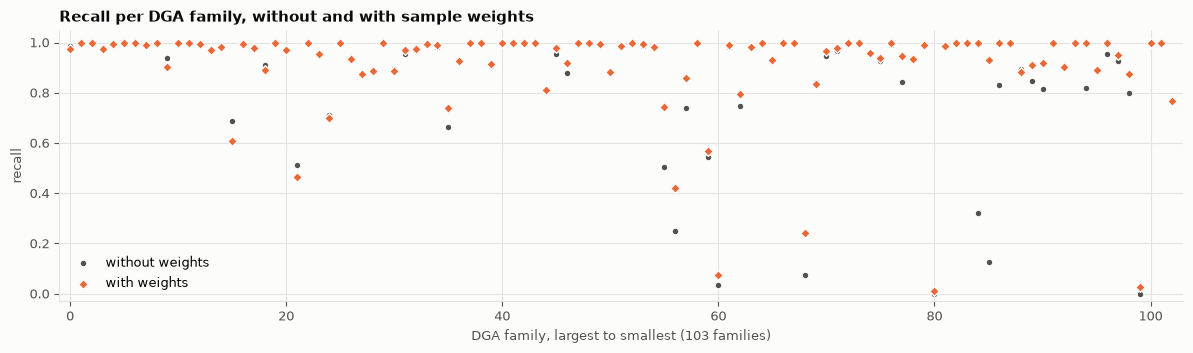

mean recall, larger half of the families: 0.942 -> 0.941
mean recall, smaller half of the families: 0.808 -> 0.868


In [13]:
recall = pd.DataFrame({
    weighted: recall_per_family(evaluate["family"], y_eval,
                                (p_dga["family", True, weighted] >= 0.5).astype(int))
    for weighted in [False, True]}).loc[family_sizes.index]
recall.columns = ["without weights", "with weights"]

fig, ax = plt.subplots(figsize=(12, 3.6))
x = np.arange(len(recall))
for column, color, marker in [("without weights", MUTED, "o"),
                              ("with weights", ORANGE, "D")]:
    ax.scatter(x, recall[column], s=24, color=color, marker=marker, label=column,
               edgecolor=SURFACE, linewidth=1, zorder=3)
ax.set_xlim(-1, len(recall))
ax.set_ylim(-0.03, 1.05)
ax.set_xlabel(f"DGA family, largest to smallest ({len(recall)} families)")
ax.set_ylabel("recall")
ax.set_title("Recall per DGA family, without and with sample weights")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

half = len(recall) // 2
print("mean recall, larger half of the families: "
      f"{recall['without weights'].iloc[:half].mean():.3f} -> "
      f"{recall['with weights'].iloc[:half].mean():.3f}")
print("mean recall, smaller half of the families: "
      f"{recall['without weights'].iloc[half:].mean():.3f} -> "
      f"{recall['with weights'].iloc[half:].mean():.3f}")

## Families Model 1 misses most

The 10 DGA families with the lowest recall (family-first, with TLD, with weights).

In [14]:
recall.sort_values("with weights").head(10).round(3)

,without weights,with weights
family,,
matsnu,0.000,0.012
bigviktor_subdomain,0.000,0.025
nymaim2,0.035,0.074
bigviktor,0.075,0.242
gozi,0.249,0.421
virut,0.512,0.464
vawtrak,0.544,0.567
qsnatch,0.689,0.607
suppobox,0.712,0.699
